<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/embeddings_mpi_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting multidimensional poverty from satellite embeddings

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

Can satellite imagery predict poverty where surveys are missing? This notebook trains machine-learning models to predict the **Multidimensional Poverty Index** (`sdg1_2_mpi`, 2012, 0–1; **higher = poorer**) of Bolivia's 339 municipalities from the 64 dimensions of Google's **satellite embeddings** (`emb` and `embpw`, 2017), and compares them with a baseline built on **night-time lights and population** (2012).

Outline:

1. **Load** the target and the features with `geo4bolivia`
2. **Models and validation**: random forest and XGBoost; random 5-fold and spatial (leave-one-department-out) cross-validation
3. **Comparison table**: R², RMSE and MAE
4. **Feature importance**: the top 20 embedding dimensions
5. **Predicted vs observed**
6. **Where the model fails**: a map of out-of-fold residuals

It builds on DS4Bolivia's `run_poverty_prediction.py` script, with a different target, a spatial validation and a lights baseline.

**A caveat on timing.** The embeddings summarise imagery of **2017**, while poverty is measured in the **2012** census. The models therefore predict 2012 poverty from the landscape five years later. Settlements, roads and land cover change slowly, so the embeddings still carry information about 2012 living conditions, but the mismatch is a limitation; the lights baseline is aligned on 2012.

## 0. Setup

In Google Colab the next cell installs what Colab lacks (a few seconds; Colab already has scikit-learn and XGBoost). Locally, `uv sync` has installed everything already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "libpysal", "esda"]
           if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns

import geo4bolivia as geo
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
from libpysal import weights
from esda.moran import Moran

import warnings
warnings.filterwarnings("ignore")

SEED = 42

## 1. Load the target and the features

Everything is keyed by `geo_id`. The two embedding datasets have the same column names (`A00`–`A63`), so we load them separately rather than with `geo.combine` (which would prefix them `emb_` and `embpw_`):

- **`emb`**: each dimension averaged over the municipality's area
- **`embpw`**: each dimension averaged with population weights, so it describes the places where people live

In [3]:
mpi = geo.load("sdg01", variables="sdg1_2_mpi", years=2012, geometry=True)
ntl = geo.load("ntl", variables="ln_t400NTLpc", years=2012)
pop = geo.load("pop", years=2012)
emb = geo.load("emb", years=2017).set_index("geo_id")
embpw = geo.load("embpw", years=2017).set_index("geo_id")

units = geo.units("municipality")
departments = geo.units("department").set_index("geo_id")["name"]

df = (mpi.merge(ntl[["geo_id", "ln_t400NTLpc"]], on="geo_id")
         .merge(pop[["geo_id", "pop"]], on="geo_id")
         .merge(units[["geo_id", "department_id"]], on="geo_id"))
df["department"] = df["department_id"].map(departments)
df["ln_pop"] = np.log(df["pop"])

DIMS = [f"A{i:02d}" for i in range(64)]
X_emb = emb.loc[df["geo_id"], DIMS].to_numpy()
X_embpw = embpw.loc[df["geo_id"], DIMS].to_numpy()
y = df["sdg1_2_mpi"].to_numpy()
groups = df["department"].to_numpy()

print(df.shape, "| missing:", int(df[["sdg1_2_mpi", "ln_t400NTLpc", "ln_pop"]].isna().sum().sum()),
      int(np.isnan(X_emb).sum()), int(np.isnan(X_embpw).sum()))
print(f"MPI 2012: mean {y.mean():.3f}, sd {y.std():.3f}, range {y.min():.3f}-{y.max():.3f}")
df[["geo_id", "name", "department", "sdg1_2_mpi", "ln_t400NTLpc", "ln_pop"]].head()

(339, 10) | missing: 0 0 0
MPI 2012: mean 0.179, sd 0.098, range 0.007-0.520


,geo_id,name,department,sdg1_2_mpi,ln_t400NTLpc,ln_pop
0,BO-01-01-01,Azurduy,Chuquisaca,0.440,11.048312,9.299041
1,BO-01-01-02,Tarvita,Chuquisaca,0.380,12.329279,9.561554
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.199,12.815315,9.320076
3,BO-01-03-01,Huacareta,Chuquisaca,0.261,12.018971,9.035351
4,BO-01-03-02,Monteagudo,Chuquisaca,0.166,14.603350,10.096847


The four feature sets:

In [4]:
feature_sets = {
    "Lights + population (2012)":        df[["ln_t400NTLpc", "ln_pop"]].to_numpy(),
    "Embeddings, area-weighted":         X_emb,
    "Embeddings, population-weighted":   X_embpw,
    "Pop.-weighted embeddings + lights": np.column_stack([X_embpw, df[["ln_t400NTLpc", "ln_pop"]]]),
}
feature_names = {
    "Lights + population (2012)":        ["ln_t400NTLpc", "ln_pop"],
    "Embeddings, area-weighted":         DIMS,
    "Embeddings, population-weighted":   DIMS,
    "Pop.-weighted embeddings + lights": DIMS + ["ln_t400NTLpc", "ln_pop"],
}
{k: v.shape for k, v in feature_sets.items()}

{'Lights + population (2012)': (339, 2),
 'Embeddings, area-weighted': (339, 64),
 'Embeddings, population-weighted': (339, 64),
 'Pop.-weighted embeddings + lights': (339, 66)}

## 2. Models and validation

Two tree ensembles, with fixed seeds:

- **Random forest**: the configuration of DS4Bolivia's script (500 trees, depth up to 10, `sqrt` features per split)
- **XGBoost**: 400 shallow boosted trees with a small learning rate and row/column subsampling

Every municipality is predicted **out of fold**, by a model that did not see it during training, under two designs:

- **Random 5-fold CV**: municipalities are shuffled into 5 folds. Neighbours of a test municipality are usually in the training set, so this measures *interpolation* within regions the model knows.
- **Spatial CV by department**: `GroupKFold` with the 9 departments as groups, i.e. leave one department out. The model must predict a whole department it has never seen, a much harder and more honest test of *transfer* to new regions.

The metrics are computed on the pooled out-of-fold predictions of all 339 municipalities.

In [5]:
def make_models():
    return {
        "Random forest": RandomForestRegressor(
            n_estimators=500, max_depth=10, min_samples_split=5, min_samples_leaf=2,
            max_features="sqrt", random_state=SEED, n_jobs=-1),
        "XGBoost": XGBRegressor(
            n_estimators=400, learning_rate=0.03, max_depth=4, min_child_weight=3,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            random_state=SEED, n_jobs=4, verbosity=0),
    }

cv_designs = {
    "Random 5-fold": (KFold(n_splits=5, shuffle=True, random_state=SEED), None),
    "Spatial (by department)": (GroupKFold(n_splits=9), groups),
}

def metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred)}

start = time.time()
rows, oof = [], {}
for fs_name, X in feature_sets.items():
    for model_name, model in make_models().items():
        for cv_name, (cv, g) in cv_designs.items():
            pred = cross_val_predict(model, X, y, cv=cv, groups=g)
            oof[(fs_name, model_name, cv_name)] = pred
            rows.append({"features": fs_name, "model": model_name, "cv": cv_name, **metrics(y, pred)})
print(f"{len(rows)} cross-validations in {time.time() - start:.0f} s")
results = pd.DataFrame(rows)

16 cross-validations in 58 s


## 3. Comparison table

In [6]:
table = (results.pivot_table(index=["features", "model"], columns="cv", values=["R2", "RMSE", "MAE"])
                .swaplevel(0, 1, axis=1)
                .reindex(columns=pd.MultiIndex.from_product([list(cv_designs), ["R2", "RMSE", "MAE"]]))
                .reindex(list(feature_sets), level=0))
table.round(3)

Random 5-fold                \
                                                           R2   RMSE    MAE   
features                          model                                       
Lights + population (2012)        Random forest         0.328  0.080  0.061   
                                  XGBoost               0.245  0.085  0.066   
Embeddings, area-weighted         Random forest         0.341  0.079  0.062   
                                  XGBoost               0.358  0.078  0.060   
Embeddings, population-weighted   Random forest         0.503  0.069  0.054   
                                  XGBoost               0.517  0.068  0.052   
Pop.-weighted embeddings + lights Random forest         0.548  0.066  0.052   
                                  XGBoost               0.582  0.063  0.050   

                                                Spatial (by department)  \
                                                                     R2   
features                          model                                   
Lights + population (2012)        Random forest                   0.135   
                                  XGBoost                        -0.050   
Embeddings, area-weighted         Random forest                  -0.037   
                                  XGBoost                        -0.032   
Embeddings, population-weighted   Random forest                   0.140   
                                  XGBoost                         0.090   
Pop.-weighted embeddings + lights Random forest                   0.229   
                                  XGBoost                         0.209   

                                                               
                                                  RMSE    MAE  
features                          model                        
Lights + population (2012)        Random forest  0.091  0.069  
                                  XGBoost        0.100  0.076  
Embeddings, area-weighted         Random forest  0.099  0.080  
                                  XGBoost        0.099  0.080  
Embeddings, population-weighted   Random forest  0.091  0.072  
                                  XGBoost        0.093  0.073  
Pop.-weighted embeddings + lights Random forest  0.086  0.067  
                                  XGBoost        0.087  0.067

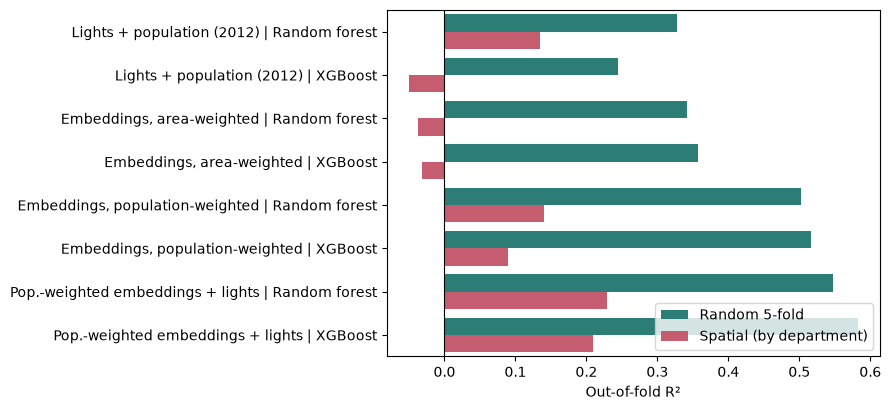

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2))
plot_df = results.assign(label=results["features"] + " | " + results["model"])
sns.barplot(data=plot_df, y="label", x="R2", hue="cv", ax=ax, palette=["#1f8a80", "#d84a64"])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Out-of-fold R²")
ax.set_ylabel("")
ax.legend(title="", loc="lower right")
plt.tight_layout()
plt.show()

**Random 5-fold CV.**

- The lights-and-population baseline explains about a third of the variance in poverty (R² 0.33 with the random forest, 0.25 with XGBoost).
- Area-weighted embeddings barely improve on it (0.34–0.36).
- **Population-weighted embeddings do much better** (0.50–0.52, RMSE 0.068–0.069 against 0.080 for the baseline). Averaging the imagery where people live, rather than over forests, salt flats and mountains, is what makes the embeddings informative about living conditions.
- Adding lights and population to them gives the best fit: **R² 0.58 with XGBoost** (RMSE 0.063, MAE 0.050) and 0.55 with the random forest.

**Spatial CV (leave one department out).** Every model loses most of its accuracy.

- The best is the random forest with population-weighted embeddings and lights (R² 0.23, RMSE 0.086), closely followed by XGBoost (0.21).
- The other sets reach at most 0.14 (population-weighted embeddings and the lights baseline, both with the random forest).
- Area-weighted embeddings get a negative R² (−0.04 and −0.03), so they predict an unseen department worse than the national mean would.
- Much of what the models learn under random CV is therefore regional: they recognise the poverty level of a department from its neighbours in the training set, and that knowledge does not transfer to a department they have never seen.

The two algorithms perform similarly. XGBoost is slightly better under random CV and the random forest under spatial CV; neither was tuned.

## 4. Feature importance

Which embedding dimensions matter? We refit both models on all 339 municipalities with the population-weighted embeddings and rank the 64 dimensions by the random forest's impurity importance and XGBoost's gain. The dimensions are abstract features learned from imagery, not named land-cover classes, so they are best read as "which parts of the embedding space separate poor from less-poor municipalities".

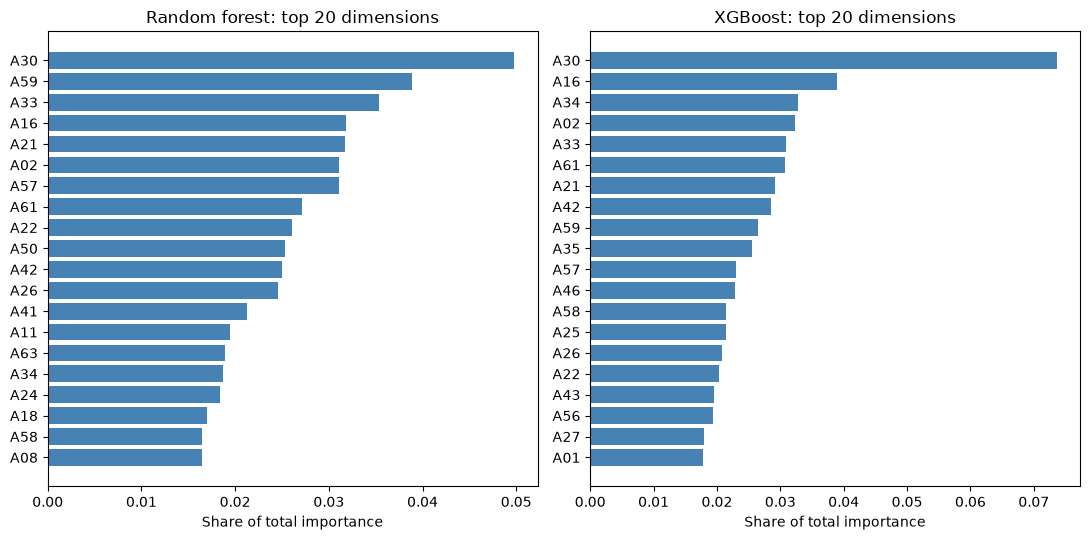

Random forest: top 5 = A30, A59, A33, A16, A21; 42 of 64 dimensions reach 80% of the importance
XGBoost: top 5 = A30, A16, A34, A02, A33; 39 of 64 dimensions reach 80% of the importance
Dimensions in both top-20 lists: 13


In [8]:
X_imp = feature_sets["Embeddings, population-weighted"]
fitted = {name: m.fit(X_imp, y) for name, m in make_models().items()}
importance = pd.DataFrame({name: m.feature_importances_ for name, m in fitted.items()}, index=DIMS)
importance = importance / importance.sum()                      # shares of total importance

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, name in zip(axes, importance.columns):
    top = importance[name].sort_values(ascending=False).head(20)[::-1]
    ax.barh(top.index, top.values, color="steelblue")
    ax.set_title(f"{name}: top 20 dimensions")
    ax.set_xlabel("Share of total importance")
plt.tight_layout()
plt.show()

for name in importance.columns:
    cum = importance[name].sort_values(ascending=False).cumsum()
    print(f"{name}: top 5 = {', '.join(cum.index[:5])}; "
          f"{(cum < 0.8).sum() + 1} of 64 dimensions reach 80% of the importance")
top20_overlap = set(importance["Random forest"].nlargest(20).index) & set(importance["XGBoost"].nlargest(20).index)
print("Dimensions in both top-20 lists:", len(top20_overlap))

In [9]:
top5 = importance["Random forest"].nlargest(5).index
corr = pd.DataFrame(X_imp, columns=DIMS)[top5].corrwith(pd.Series(y)).round(2)
print("Correlation of the RF top-5 dimensions with MPI:", corr.to_dict())

Correlation of the RF top-5 dimensions with MPI: {'A30': 0.49, 'A59': 0.32, 'A33': 0.33, 'A16': -0.21, 'A21': -0.28}


Dimension **A30** is the most important for both models (5.0% of the random forest's importance and 7.4% of XGBoost's gain). It is also the dimension most correlated with poverty (+0.49). Beyond it, importance is spread thinly:

- 42 (random forest) and 39 (XGBoost) of the 64 dimensions are needed to reach 80% of the total importance.
- 13 dimensions appear in both top-20 lists.

No small subset of dimensions carries the signal. Impurity and gain importances are also unstable when features are correlated, as embedding dimensions are, so the ranks beyond the first few are indicative only.

## 5. Predicted vs observed

Model shown: XGBoost with Pop.-weighted embeddings + lights


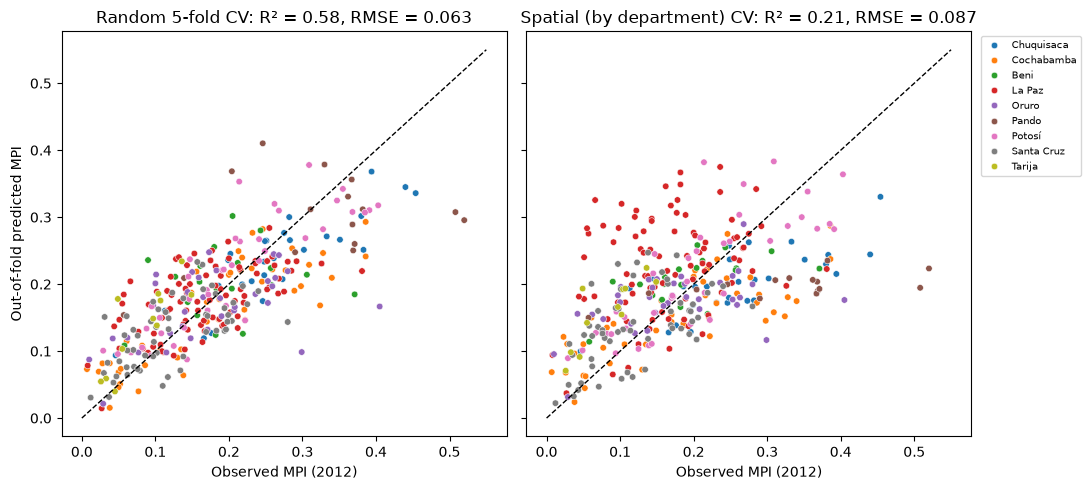

In [10]:
BEST_FEATURES = "Pop.-weighted embeddings + lights"
best_model = (results[results["features"] == BEST_FEATURES]
              .groupby("model")["R2"].mean().idxmax())
print("Model shown:", best_model, "with", BEST_FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, cv_name in zip(axes, cv_designs):
    pred = oof[(BEST_FEATURES, best_model, cv_name)]
    m = metrics(y, pred)
    sns.scatterplot(x=y, y=pred, hue=df["department"], s=22, ax=ax, legend=(ax is axes[1]))
    ax.plot([0, 0.55], [0, 0.55], color="black", lw=1, ls="--")
    ax.set_title(f"{cv_name} CV: R² = {m['R2']:.2f}, RMSE = {m['RMSE']:.3f}")
    ax.set_xlabel("Observed MPI (2012)")
    ax.set_ylabel("Out-of-fold predicted MPI")
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

The figure shows XGBoost with population-weighted embeddings and lights, the model with the best average R² across the two designs.

- **Under random CV** the points follow the diagonal but are compressed towards the mean, as is typical of tree ensembles. The poorest municipalities (MPI above 0.4) are predicted too low and the least poor ones too high.
- **Under spatial CV** the cloud is much wider, and colours separate. Many La Paz municipalities are predicted poorer than they are, while the poorest municipalities of Pando and Chuquisaca are predicted far less poor.

## 6. Where the model fails: out-of-fold residuals

Residuals are observed minus predicted MPI: **red** municipalities are poorer than the model predicts, **blue** ones less poor.

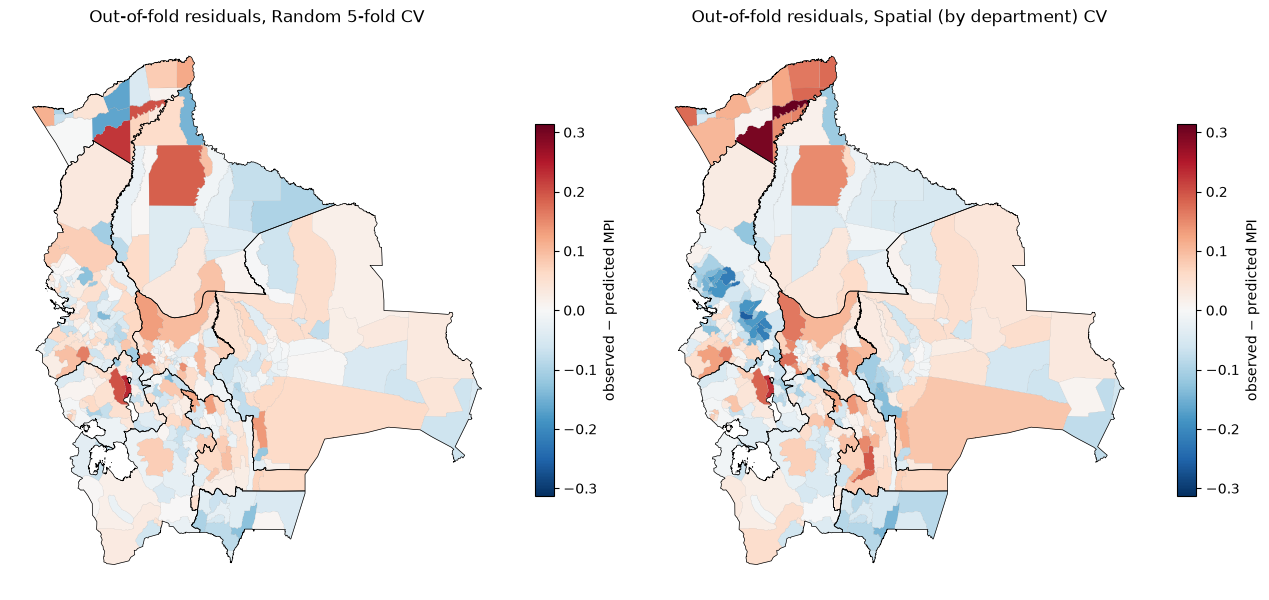

In [11]:
gdf = mpi[["geo_id", "geometry"]].merge(df[["geo_id", "name", "department", "sdg1_2_mpi"]], on="geo_id")
gdf = gdf.to_crs(geo.config()["equal_area_crs"])
for cv_name, col in zip(cv_designs, ["resid_random", "resid_spatial"]):
    gdf[col] = y - oof[(BEST_FEATURES, best_model, cv_name)]

# department outlines
dep_lines = geo.boundaries("department").to_crs(gdf.crs).boundary

lim = np.abs(gdf[["resid_random", "resid_spatial"]].to_numpy()).max()
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, (cv_name, col) in zip(axes, zip(cv_designs, ["resid_random", "resid_spatial"])):
    gdf.plot(column=col, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim), linewidth=0.05, edgecolor="grey",
             legend=True, legend_kwds={"shrink": 0.6, "label": "observed − predicted MPI"}, ax=ax)
    dep_lines.plot(ax=ax, color="black", linewidth=0.5)
    ax.set_title(f"Out-of-fold residuals, {cv_name} CV")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

Are the errors spatially clustered? Moran's I of the residuals with queen contiguity:

In [12]:
w = weights.Queen.from_dataframe(gdf, use_index=False)
w.transform = "r"
print("Islands:", w.islands)
np.random.seed(SEED)                     # reproducible permutation p-values
for col in ["resid_random", "resid_spatial"]:
    mi = Moran(gdf[col], w, permutations=999)
    print(f"{col}: Moran's I = {mi.I:.3f}, p = {mi.p_sim:.3f}")

('WARNING: ', 207, ' is an island (no neighbors)')
Islands: [207]
resid_random: Moran's I = 0.089, p = 0.003
resid_spatial: Moran's I = 0.462, p = 0.001


In [13]:
by_dep = (gdf.groupby("department")
             .agg(municipalities=("resid_spatial", "size"),
                  mean_residual=("resid_spatial", "mean"),
                  rmse=("resid_spatial", lambda r: np.sqrt(np.mean(r ** 2))))
             .sort_values("rmse", ascending=False))
by_dep.round(3)

,municipalities,mean_residual,rmse
department,,,
Pando,15,0.125,0.165
La Paz,87,-0.063,0.107
Chuquisaca,29,0.056,0.087
Tarija,11,-0.075,0.080
Cochabamba,47,0.027,0.075
Oruro,35,-0.001,0.074
Santa Cruz,56,-0.016,0.060
Beni,19,-0.011,0.059
Potosí,40,-0.010,0.058


In [14]:
cols = ["name", "department", "sdg1_2_mpi", "resid_spatial"]
print("Poorer than predicted (spatial CV):")
print(gdf.nlargest(5, "resid_spatial")[cols].round(3).to_string(index=False))
print("\nLess poor than predicted (spatial CV):")
print(gdf.nsmallest(5, "resid_spatial")[cols].round(3).to_string(index=False))

Poorer than predicted (spatial CV):
     name department  sdg1_2_mpi  resid_spatial
San Pedro      Pando       0.508          0.313
  El Sena      Pando       0.520          0.297
 El Choro      Oruro       0.405          0.229
  Azurduy Chuquisaca       0.440          0.196
   Toledo      Oruro       0.299          0.182

Less poor than predicted (spatial CV):
     name department  sdg1_2_mpi  resid_spatial
Yanacachi     La Paz       0.066         -0.260
  Tipuani     La Paz       0.055         -0.228
   Mapiri     La Paz       0.057         -0.218
    Quime     La Paz       0.102         -0.218
  Cajuata     La Paz       0.077         -0.210


- **Under random CV** the residuals are small and only weakly clustered (Moran's I = 0.088, p = 0.004).
- **Under spatial CV** they are strongly clustered (Moran's I = 0.468, p = 0.001). The errors are shared by whole departments: the model carries the poverty level of the training departments into the held-out one.
- **Pando** is the hardest department (RMSE 0.165). It is poorer than predicted by 0.125 on average, and two of its municipalities, San Pedro and El Sena, by about 0.3.
- Tarija (−0.075) and **La Paz** (−0.063) are less poor than predicted. In La Paz the largest errors are in the Yungas and the gold-mining valleys (Yanacachi, Tipuani, Mapiri, Cajuata, Quime), predicted more than 0.2 too poor.
- Chuquisaca (+0.056) and two Oruro municipalities (El Choro, Toledo) are poorer than predicted.

## 7. Summary

- **Satellite embeddings carry real information about poverty.** Under random cross-validation, population-weighted embeddings explain about half of the variance in municipal MPI (R² 0.50–0.52), against a third for night-time lights and population (0.25–0.33). Combining both reaches 0.58.
- **How the embeddings are aggregated matters.** Population-weighted averages clearly beat area-weighted ones (0.50–0.52 against 0.34–0.36).
- **Predicting an unseen region is much harder.** With whole departments held out, the best R² falls to 0.23 and errors cluster by department. These models can fill gaps *within* regions that have survey data. They should not be used to map poverty blindly in a region with no ground truth, unless some local data are available to calibrate them.
- **Caveats.** The embeddings describe 2017 and poverty 2012. There are only 339 observations and the hyperparameters were not tuned. Importances are indicative, and the predictions are associations, not causal effects.

Related notebooks: `esda_heterogeneity` (how the lights–poverty relationship varies across space) and `esda_inequality`.